# 07 Final-report analyses (summary)

The last step of the pipeline. It summarises the secondary analyses written for the course report, all computed on the
**locked** model and alert policy v3 (nothing is tuned on the test split):

| Section | Script (run order) | Output folder |
|---|---|---|
| 1. Severity and literature operating point, baselines, decision curves | `scripts/run_final_analyses.py` | `artifacts/reports/final_analyses_v1/` |
| 2. Exploratory data analysis (training split) | `scripts/run_eda.py` | `artifacts/reports/eda_v1/` |
| 3. CareVue <-> MetaVision transfer | `scripts/run_system_shift.py` | `artifacts/reports/system_shift_v1/` |
| 4. Local recalibration of a transported model | `scripts/run_recalibration.py` | `artifacts/reports/system_recalibration_v1/` |
| 5. Fairness by insurance and recorded ethnicity | `scripts/run_fairness.py` | `artifacts/reports/fairness_structured_v1/` |
| Figures | `scripts/make_report_figures.py` | `artifacts/reports/figures/` |

This notebook only **reads the committed aggregate tables and figures**, so it runs without MIMIC-III access. Every
number is explained in `docs/FINAL-ANALYSES.md`; reproduction steps are in `INSTALL.md`.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "pipeline" else Path.cwd()
R = ROOT / "artifacts" / "reports"
FIG = R / "figures"
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

def show(name, width=820):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

## 0. System overview and cohort

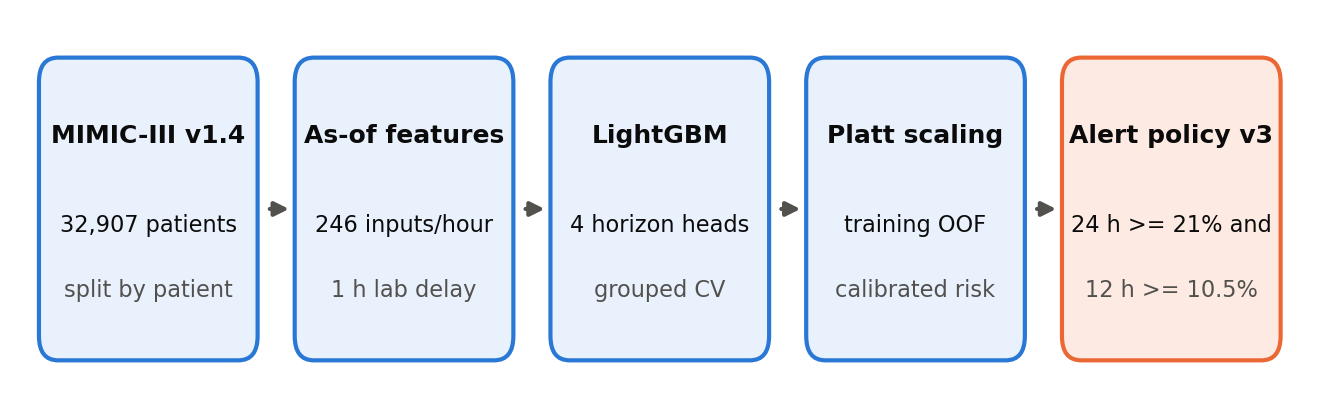

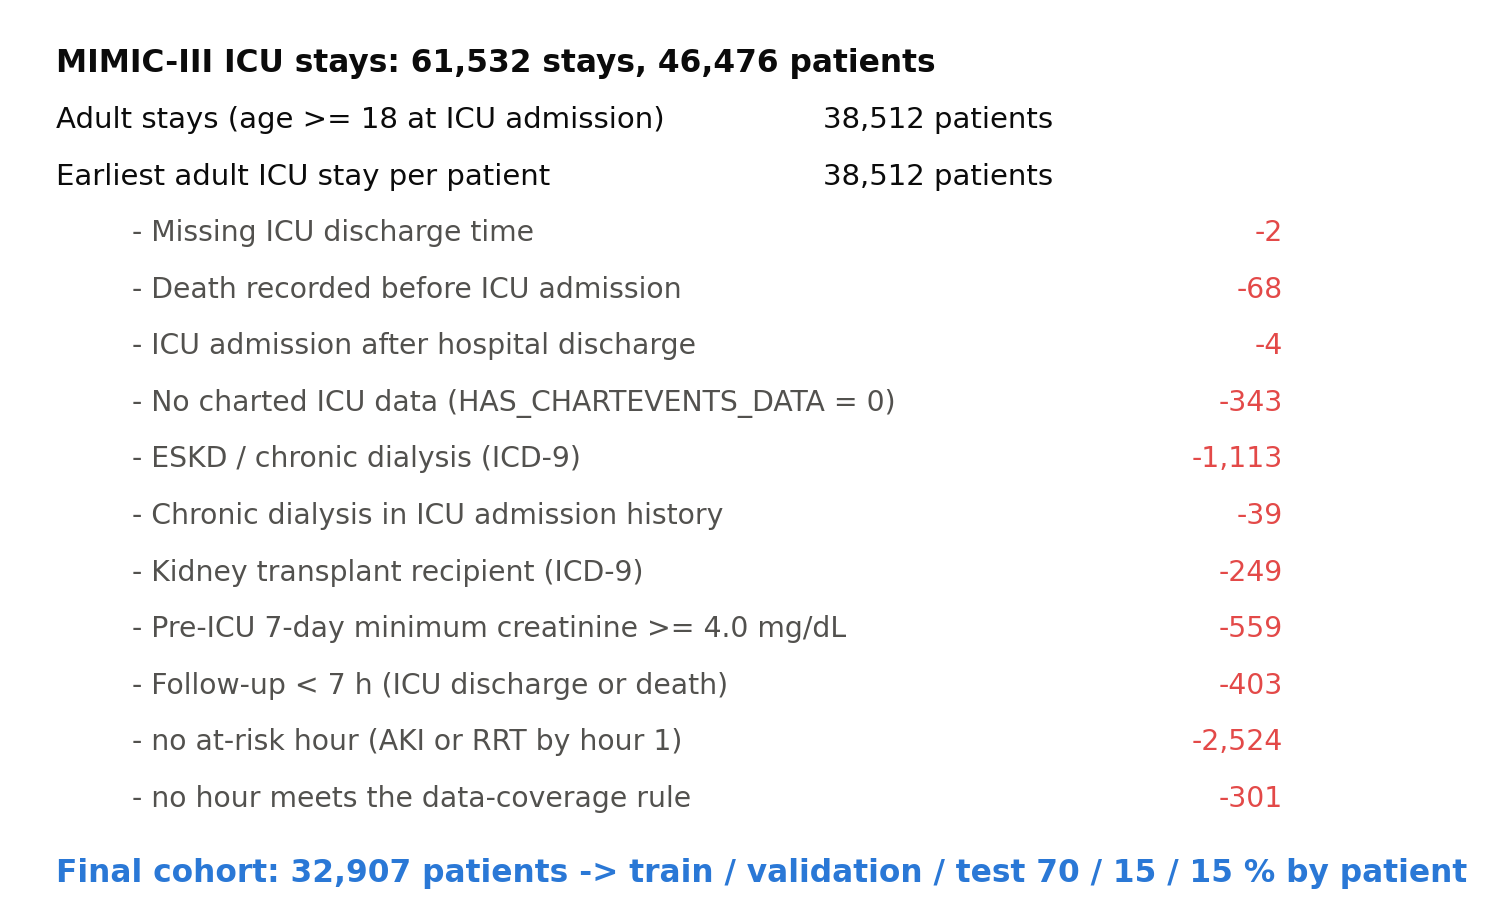

split,train,validation,test,all
patients,22998,4950,4959,32907
age_years_median_iqr,65.4 [52.1-77.8],65.4 [52.4-77.7],65.8 [52.0-78.5],65.4 [52.1-77.9]
male_pct,56.6,57.4,55.7,56.6
emergency_admission_pct,80.6,80.3,81.1,80.6
icu_los_hours_median_iqr,49.5 [28.6-95.4],49.3 [28.4-95.2],50.8 [28.7-98.7],49.7 [28.6-95.9]
icu_death_pct,6.9,6.6,6.4,6.8
carevue_pct,57.2,57.2,57.2,57.2
metavision_pct,42.7,42.6,42.6,42.7
creatinine_aki_pct,22.9,23.1,23.3,23.0
aki_stage1_pct,16.5,16.9,16.9,16.6


In [2]:
show("fig_pipeline")
show("fig_cohort_flow", 640)
pd.read_csv(R / "eda_v1" / "table1_by_split.csv").set_index("split").T

## 1. Exploratory data analysis (training split)

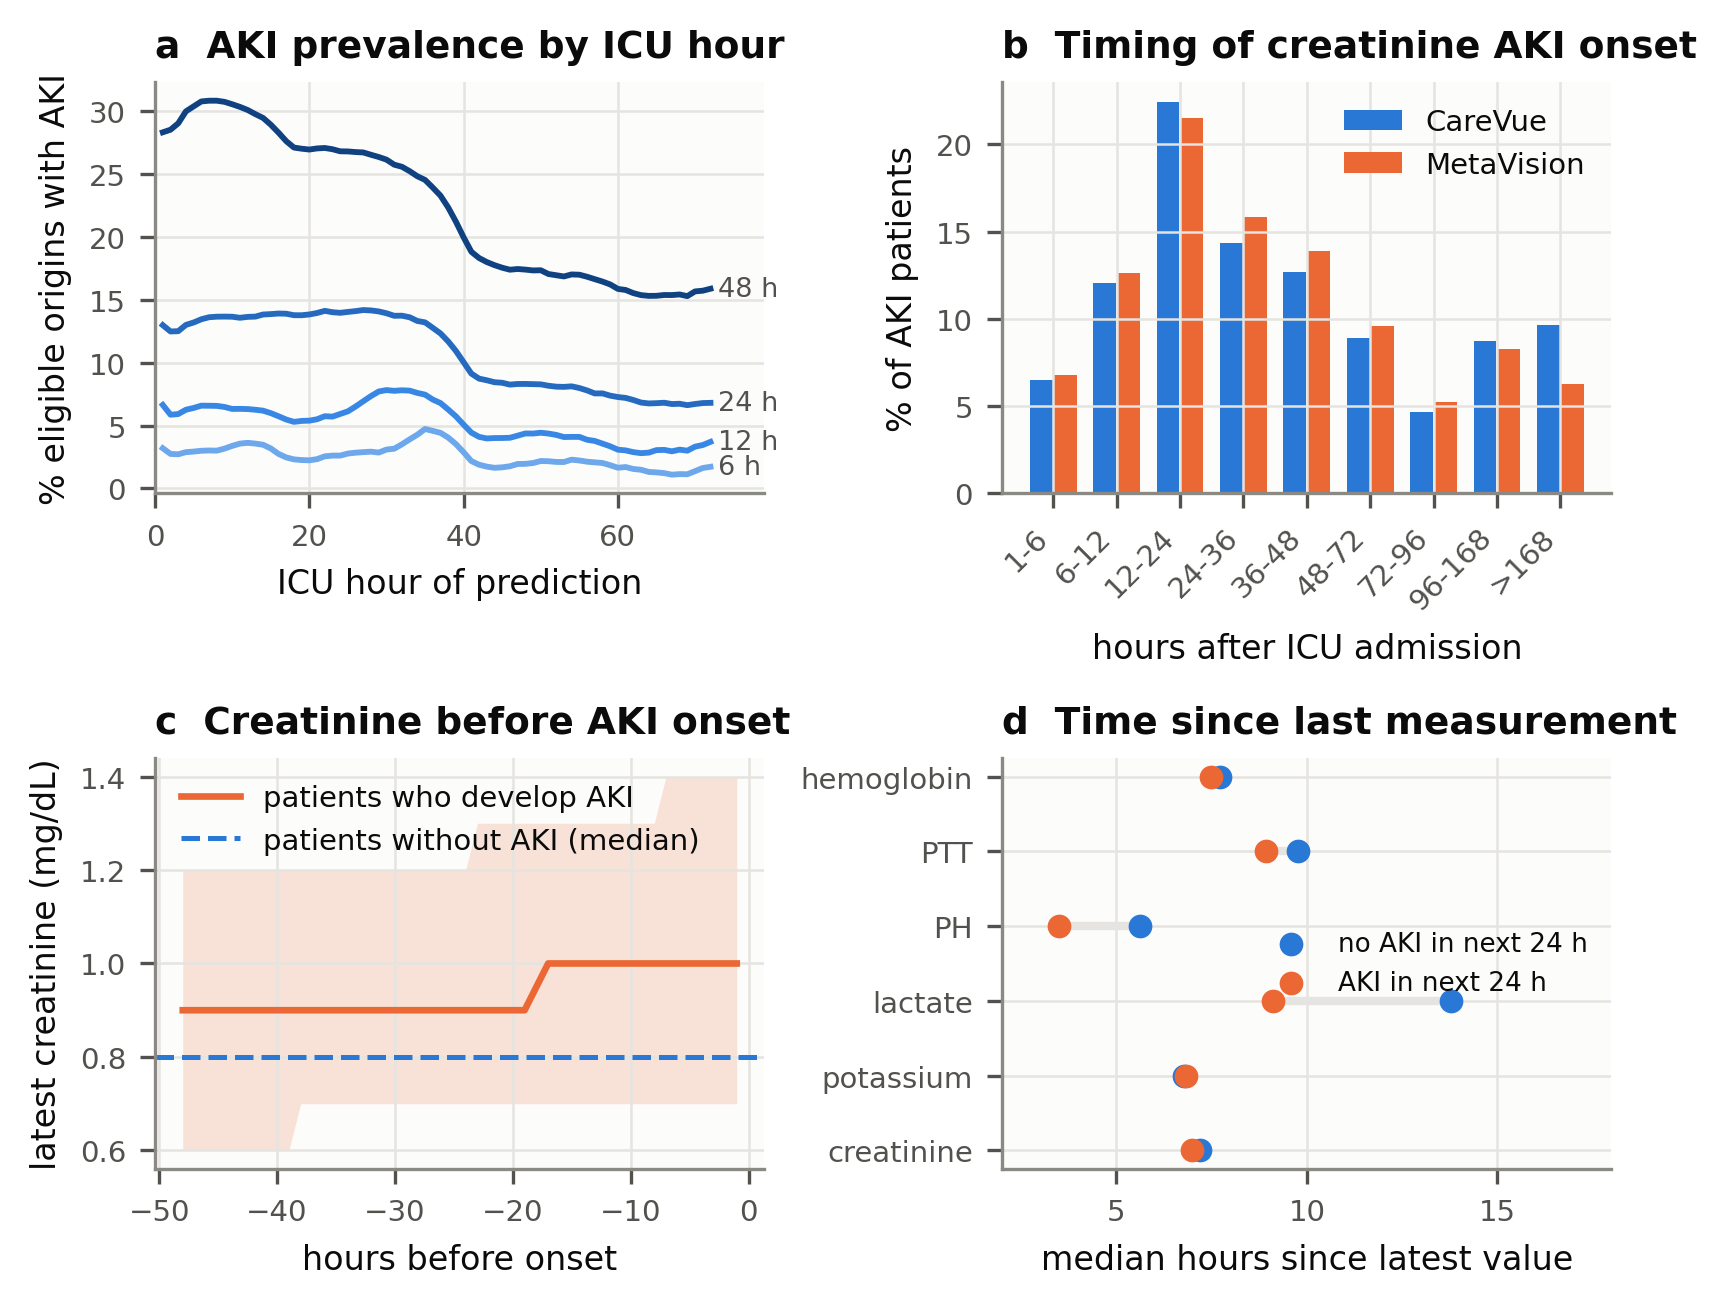

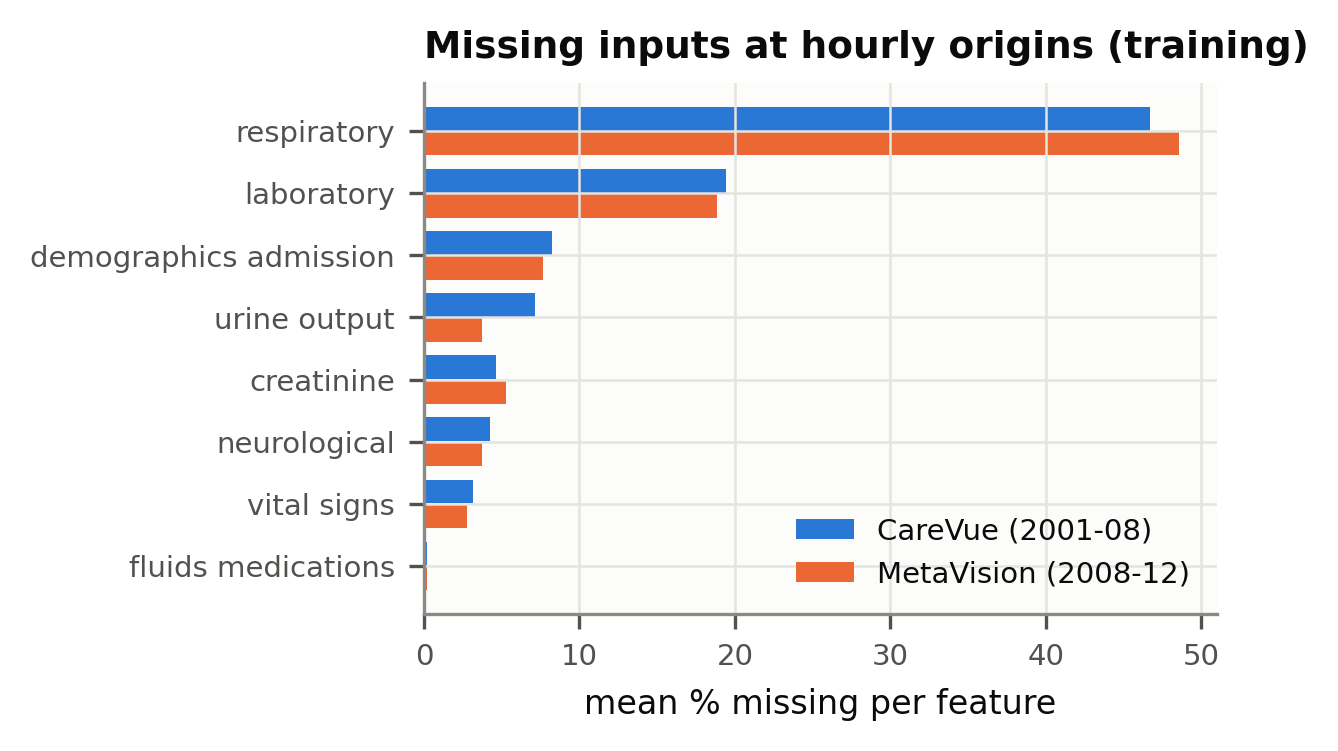

In [3]:
show("fig_eda")
show("fig_missingness", 560)

## 2. Discrimination, calibration and baselines (test split)

horizon_h,6,12,24,48
label,,,,
LightGBM no_dc (stored features),0.866,0.841,0.817,0.792
LightGBM no_dc (locked system),0.866,0.841,0.817,0.792
LightGBM full,0.864,0.839,0.814,0.793
XGBoost full,0.863,0.839,0.814,0.792
Random forest full,0.843,0.820,0.794,0.778
Logistic regression full,0.819,0.805,0.788,0.774
Creatinine-only logistic regression,0.718,0.714,0.703,0.684
Creatinine rise from 48 h minimum (score),0.636,0.633,0.618,0.581


,model,auroc,auroc_ci_low,auroc_ci_high,auroc_minus_primary,delta_ci_low,delta_ci_high
16,primary,0.817,0.803,0.831,NaN,NaN,NaN
17,lightgbm__no_dc,0.817,0.803,0.831,6.196e-05,-1.776e-05,1.534e-04
18,lightgbm__full,0.814,0.799,0.829,-2.968e-03,-5.740e-03,7.737e-05
19,xgboost__full,0.814,0.800,0.829,-3.322e-03,-6.744e-03,4.881e-04
20,rf__full,0.794,0.779,0.809,-2.304e-02,-2.885e-02,-1.740e-02
21,lr__full,0.788,0.771,0.804,-2.927e-02,-3.870e-02,-2.053e-02
22,creatinine_lr,0.703,0.684,0.721,-1.144e-01,-1.284e-01,-9.903e-02
23,creatinine_rise,0.618,0.603,0.634,-1.991e-01,-2.155e-01,-1.793e-01


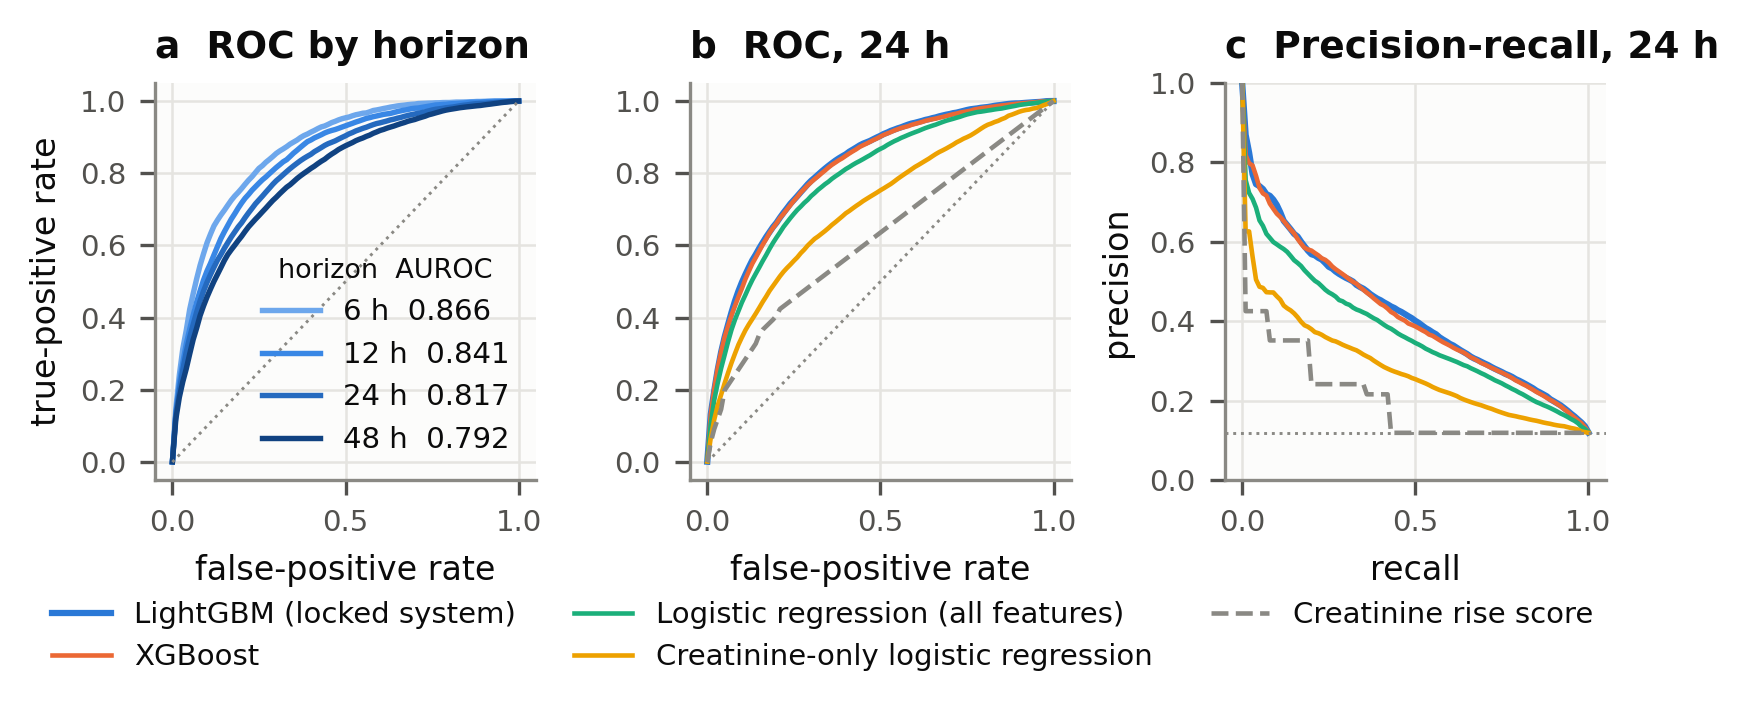

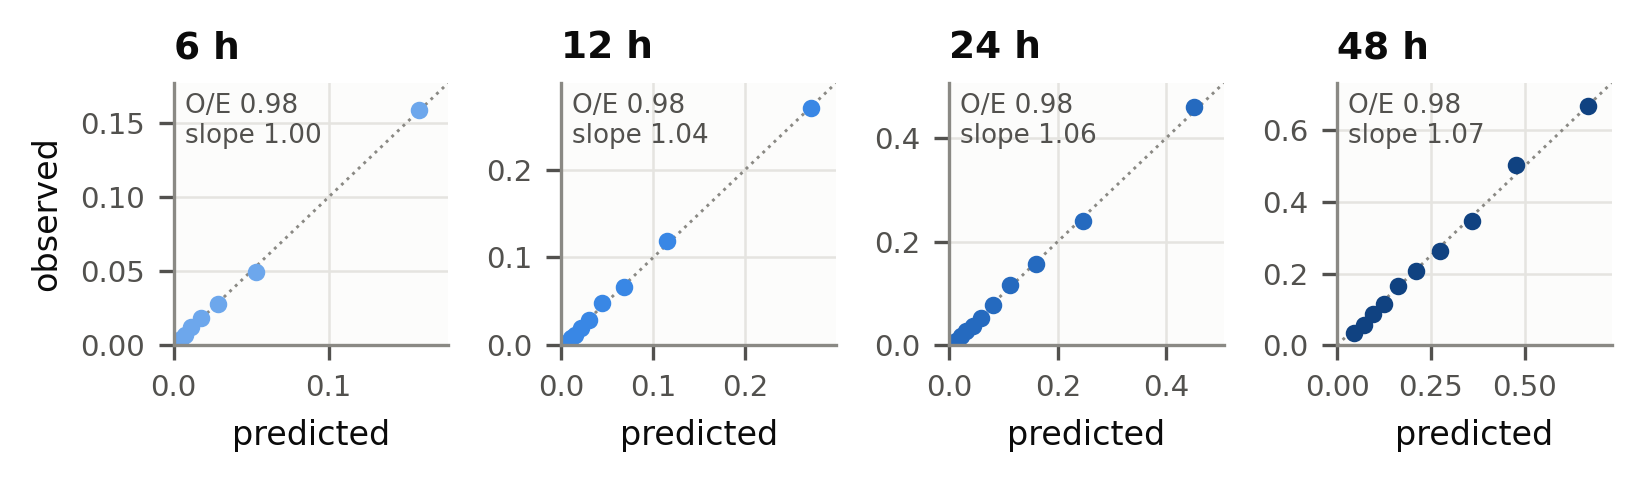

In [4]:
b = pd.read_csv(R / "final_analyses_v1" / "baseline_metrics.csv")
display(b.pivot(index="label", columns="horizon_h", values="auroc").sort_values(24, ascending=False))
d = pd.read_csv(R / "final_analyses_v1" / "baseline_auroc_differences.csv")
display(d[d["horizon_h"] == 24][["model", "auroc", "auroc_ci_low", "auroc_ci_high", "auroc_minus_primary", "delta_ci_low", "delta_ci_high"]])
show("fig_roc_pr")
show("fig_calibration")

## 3. Alerting: severity, operating point, trade-off and decision curves

,policy,alert_ppv,false_alerts_per_true_alert,event_detection_rate,lead_time_median_h,alerts_per_patient_day
0,policy_v3,0.335,1.986,0.717,11.637,0.418
1,demo_v1,0.340,1.944,0.766,12.936,0.798


,stratum,events,detection_rate_24h,detection_24h_ci_low,detection_24h_ci_high,detection_rate_48h,lead_time_median_h
0,all events,959,0.717,0.688,0.745,0.766,11.637
1,max stage 1,693,0.681,0.645,0.715,0.732,12.005
2,max stage 2,144,0.764,0.688,0.826,0.799,11.330
3,max stage 3,122,0.869,0.798,0.918,0.926,9.508
4,max stage 2-3,266,0.812,0.761,0.854,0.857,10.860
5,went on to RRT,41,0.976,0.874,0.996,0.976,10.672


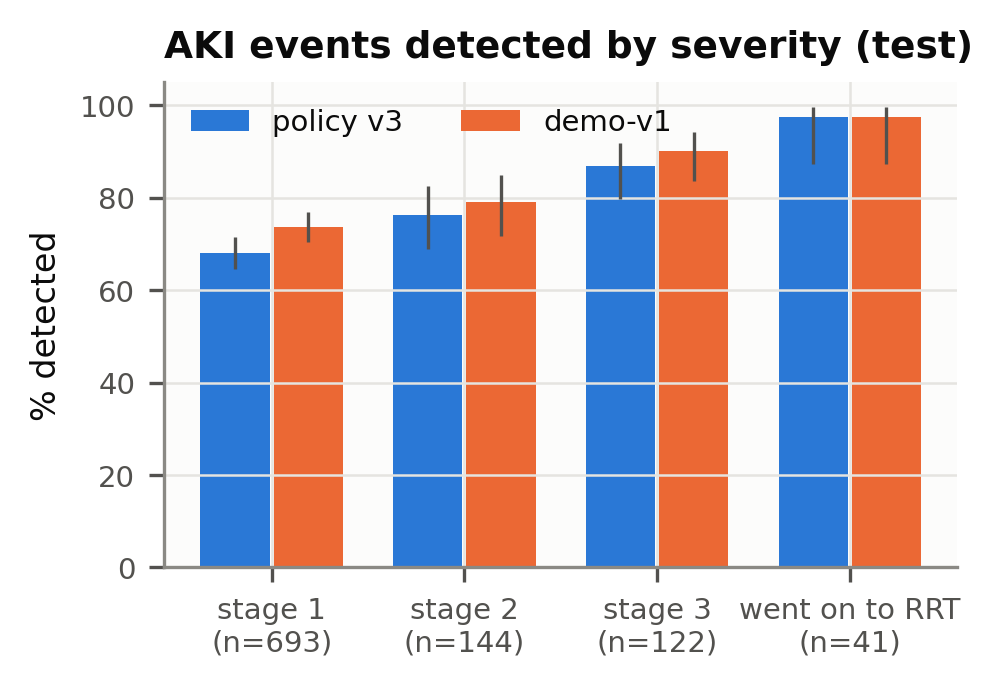

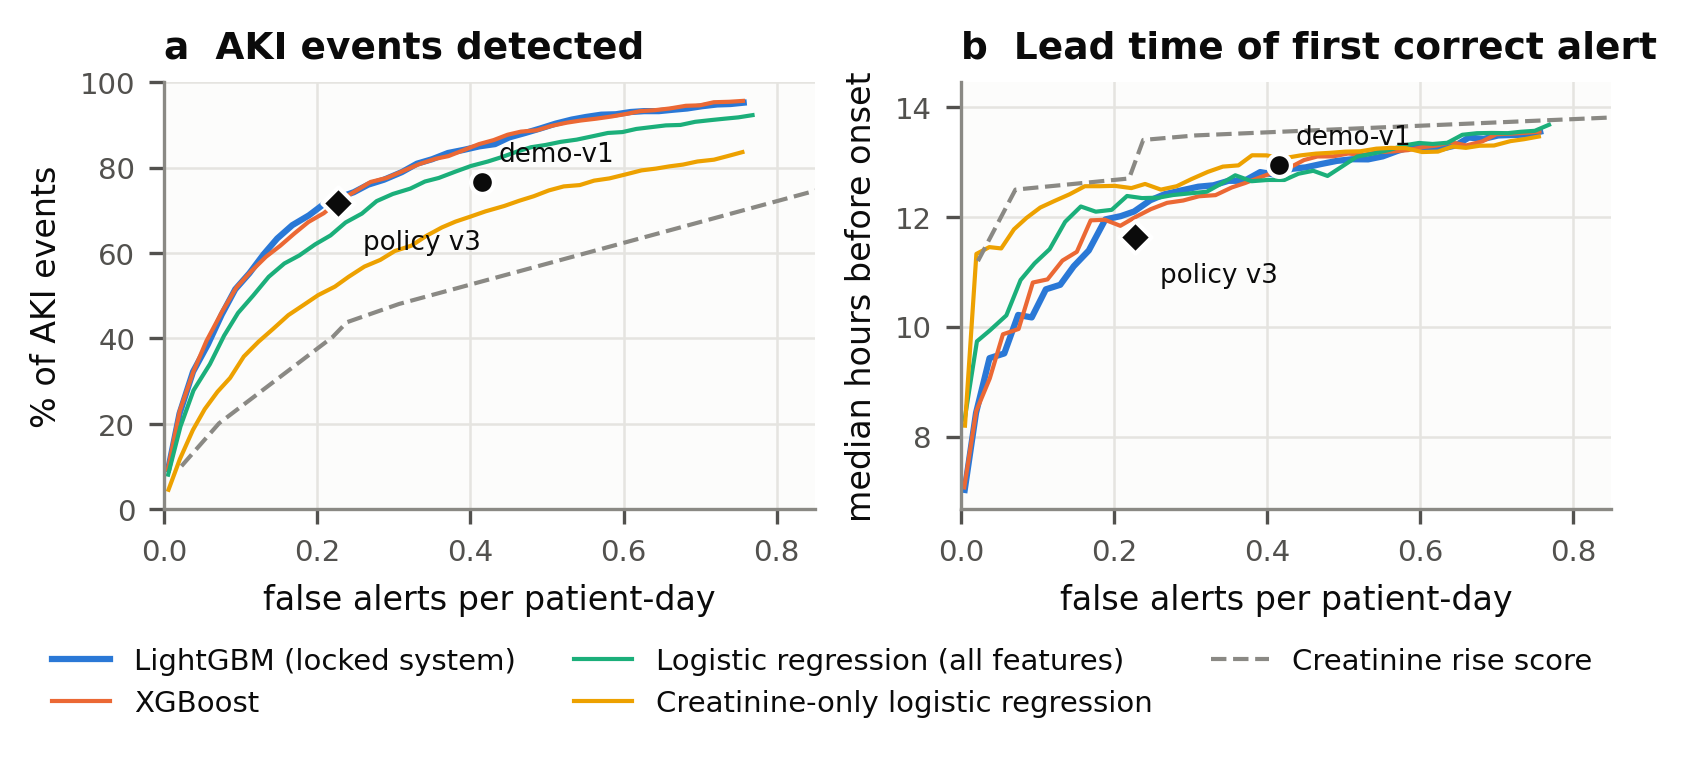

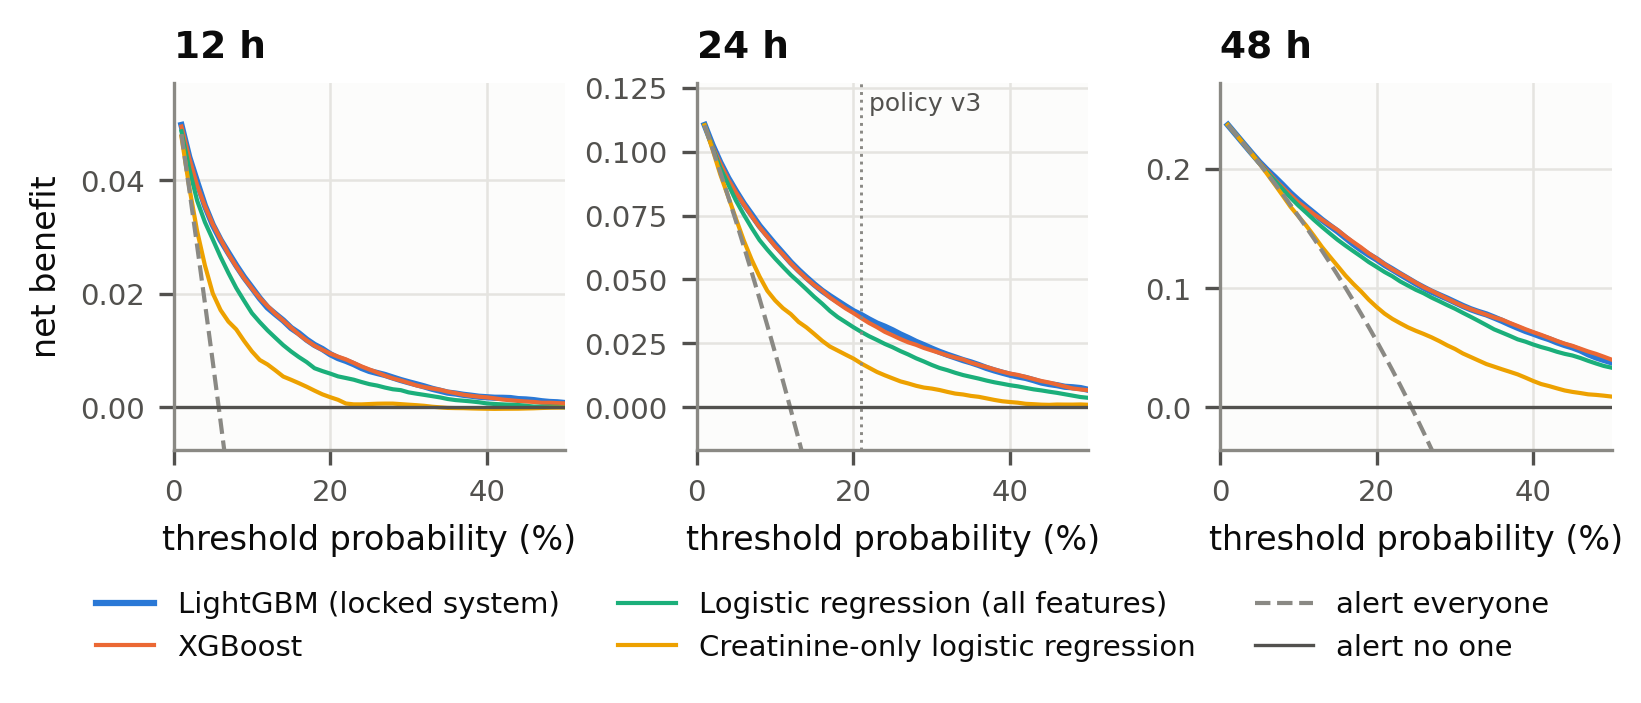

In [5]:
display(pd.read_csv(R / "final_analyses_v1" / "operating_points.csv"))
s = pd.read_csv(R / "final_analyses_v1" / "severity_detection.csv")
display(s[s["policy"] == "policy_v3"][["stratum", "events", "detection_rate_24h", "detection_24h_ci_low", "detection_24h_ci_high", "detection_rate_48h", "lead_time_median_h"]])
show("fig_severity", 560)
show("fig_alert_tradeoff")
show("fig_decision_curve")

## 4. Interpretability and subgroups (from the locked test evaluation, notebook 06)

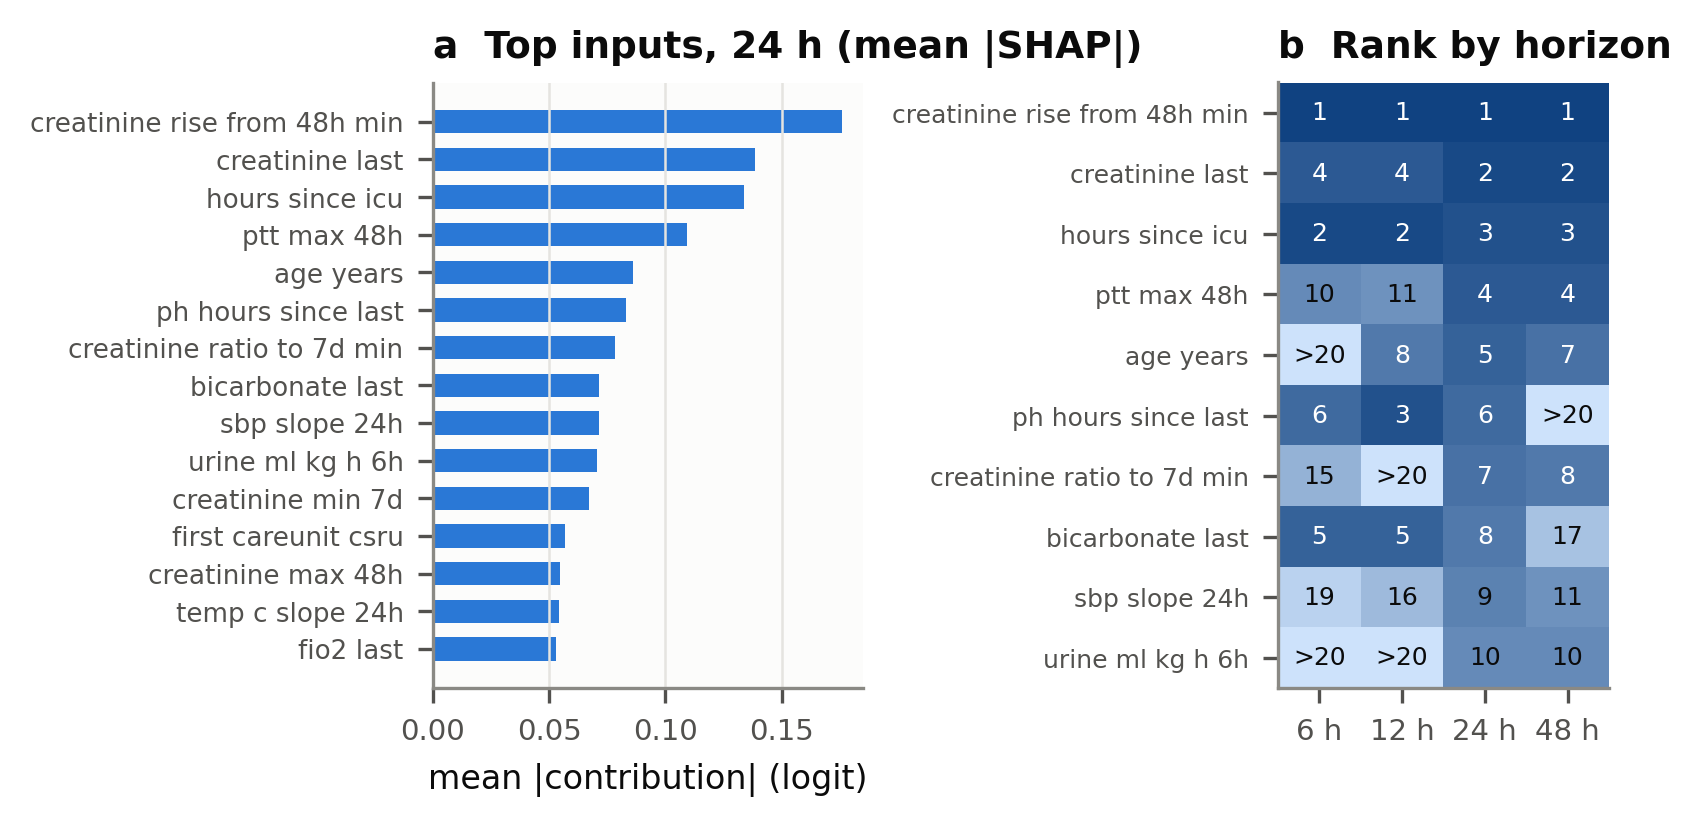

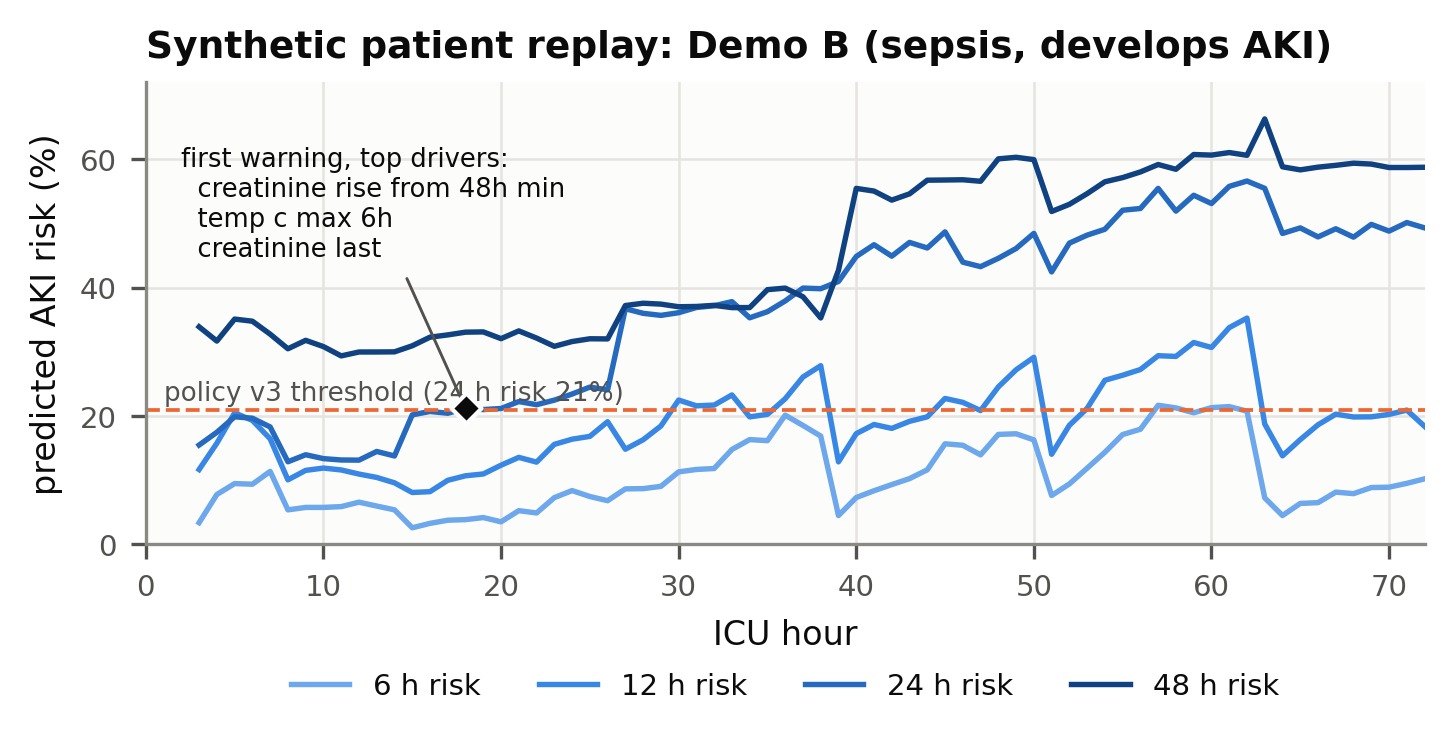

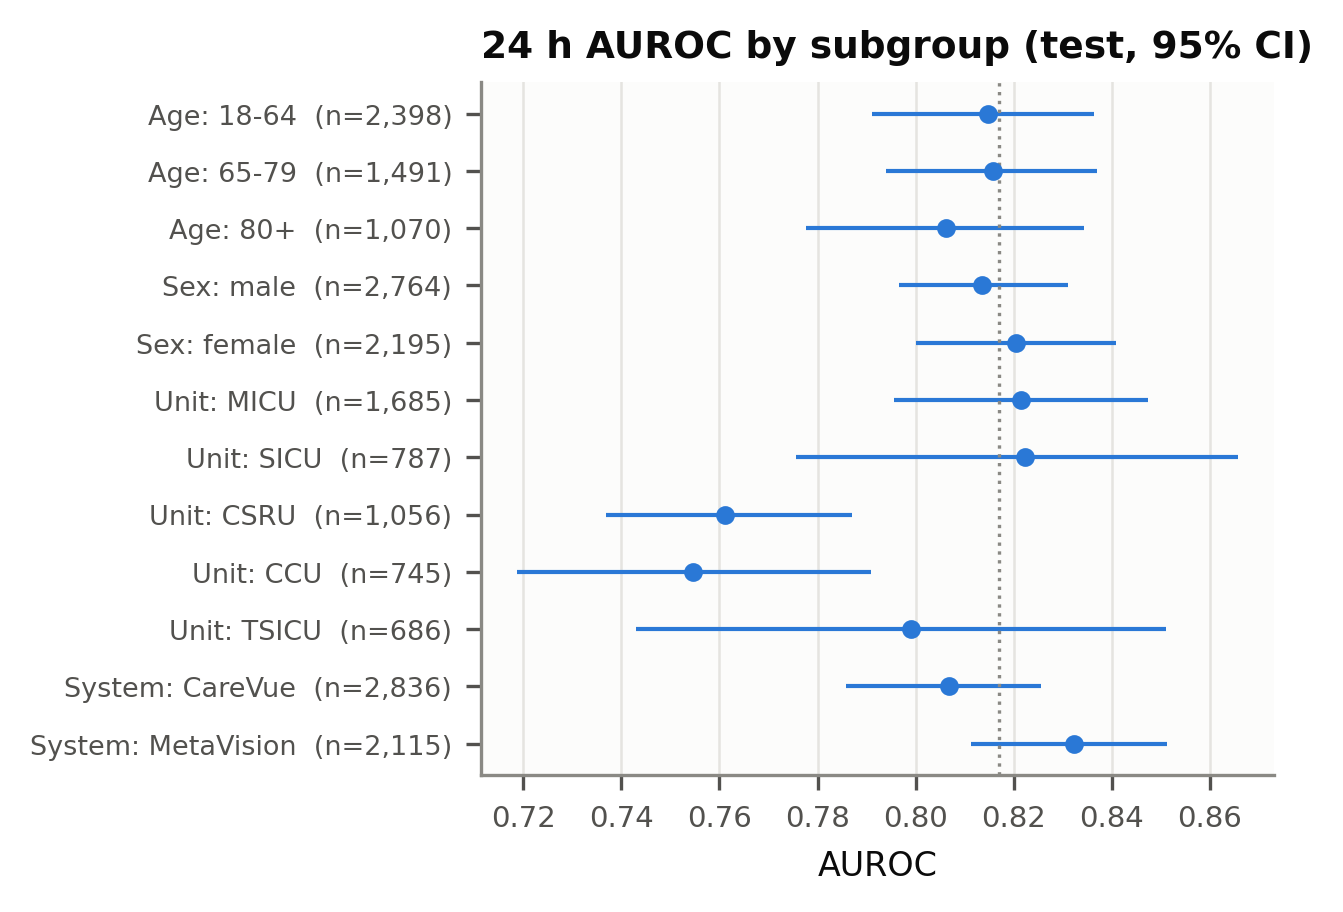

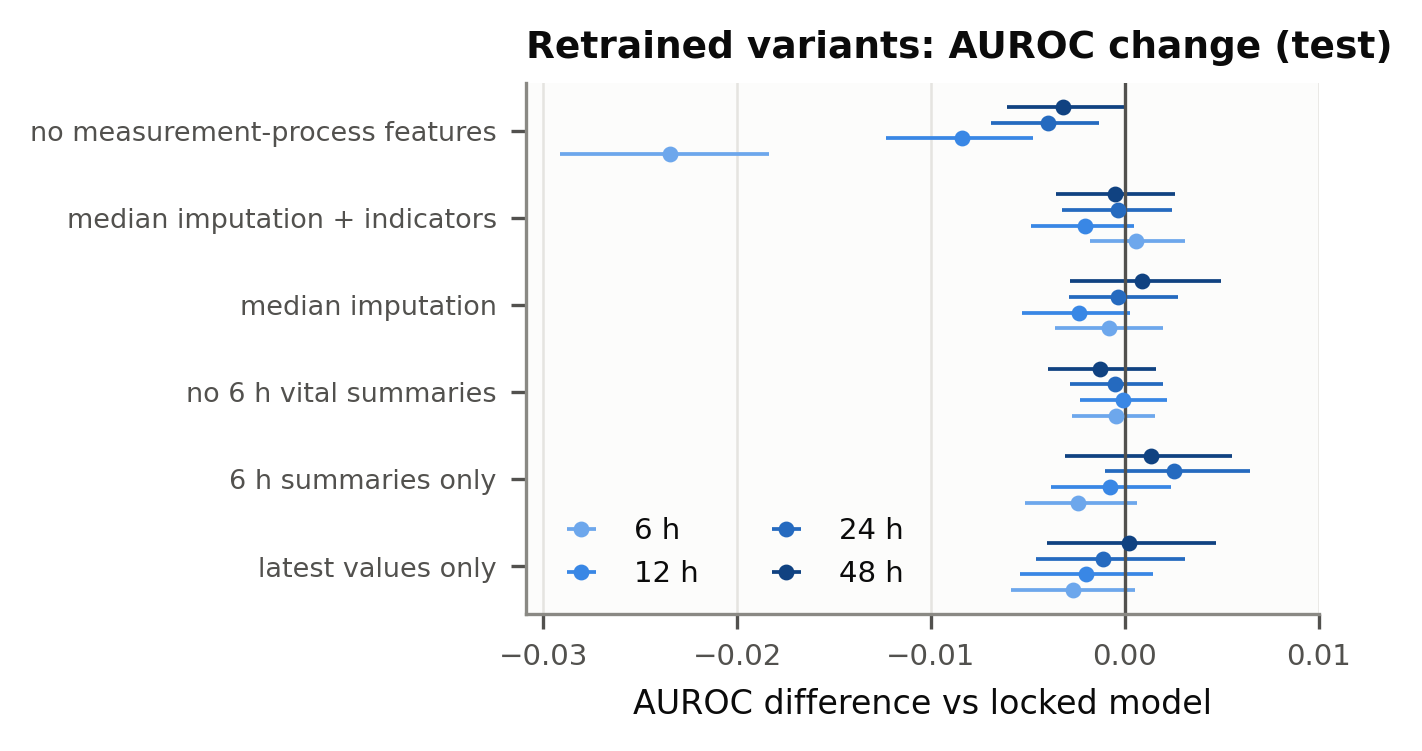

In [6]:
show("fig_shap")
show("fig_patient_example")
show("fig_subgroups", 560)
show("fig_retrain_sensitivity", 560)

## 5. Generalisability: CareVue <-> MetaVision transfer and local recalibration

horizon_h                          6      12     24     48
target_system model                                       
carevue       reference         0.867  0.835  0.807  0.780
              train_carevue     0.855  0.823  0.792  0.768
              train_metavision  0.839  0.806  0.782  0.760
metavision    reference         0.866  0.850  0.832  0.810
              train_carevue     0.833  0.824  0.806  0.785
              train_metavision  0.862  0.843  0.821  0.796

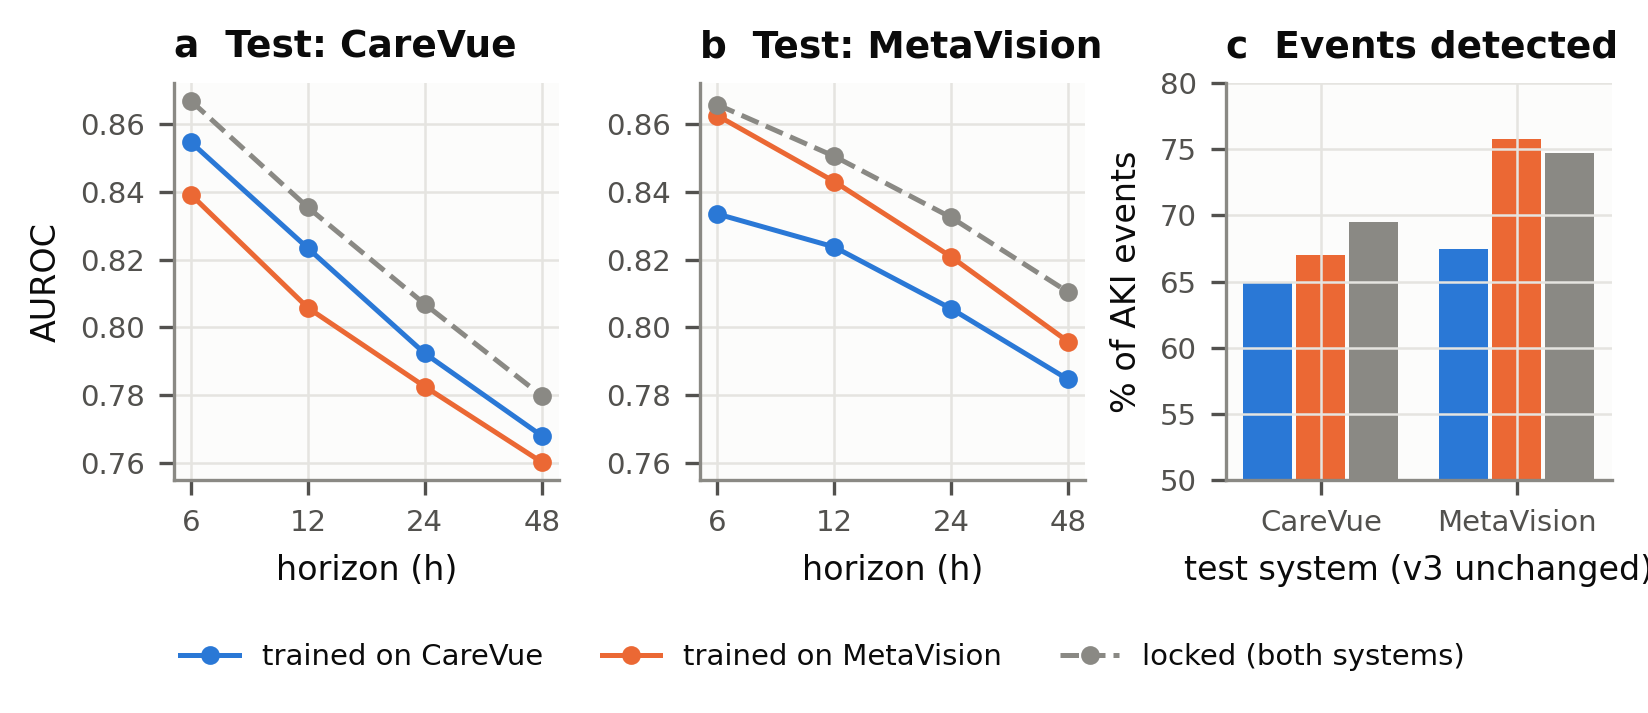

,target_system,model,event_detection_rate,false_alerts_per_patient_day,alert_ppv,alerts_per_patient_day
0,metavision,train_carevue (source calibration),0.674,0.190,0.365,0.371
1,metavision,train_carevue (recalibrated on target validation),0.712,0.224,0.340,0.431
2,metavision,train_metavision (within-system),0.758,0.212,0.373,0.422
3,carevue,train_metavision (source calibration),0.670,0.258,0.297,0.441
4,carevue,train_metavision (recalibrated on target valid...,0.649,0.237,0.308,0.411
5,carevue,train_carevue (within-system),0.649,0.238,0.301,0.415


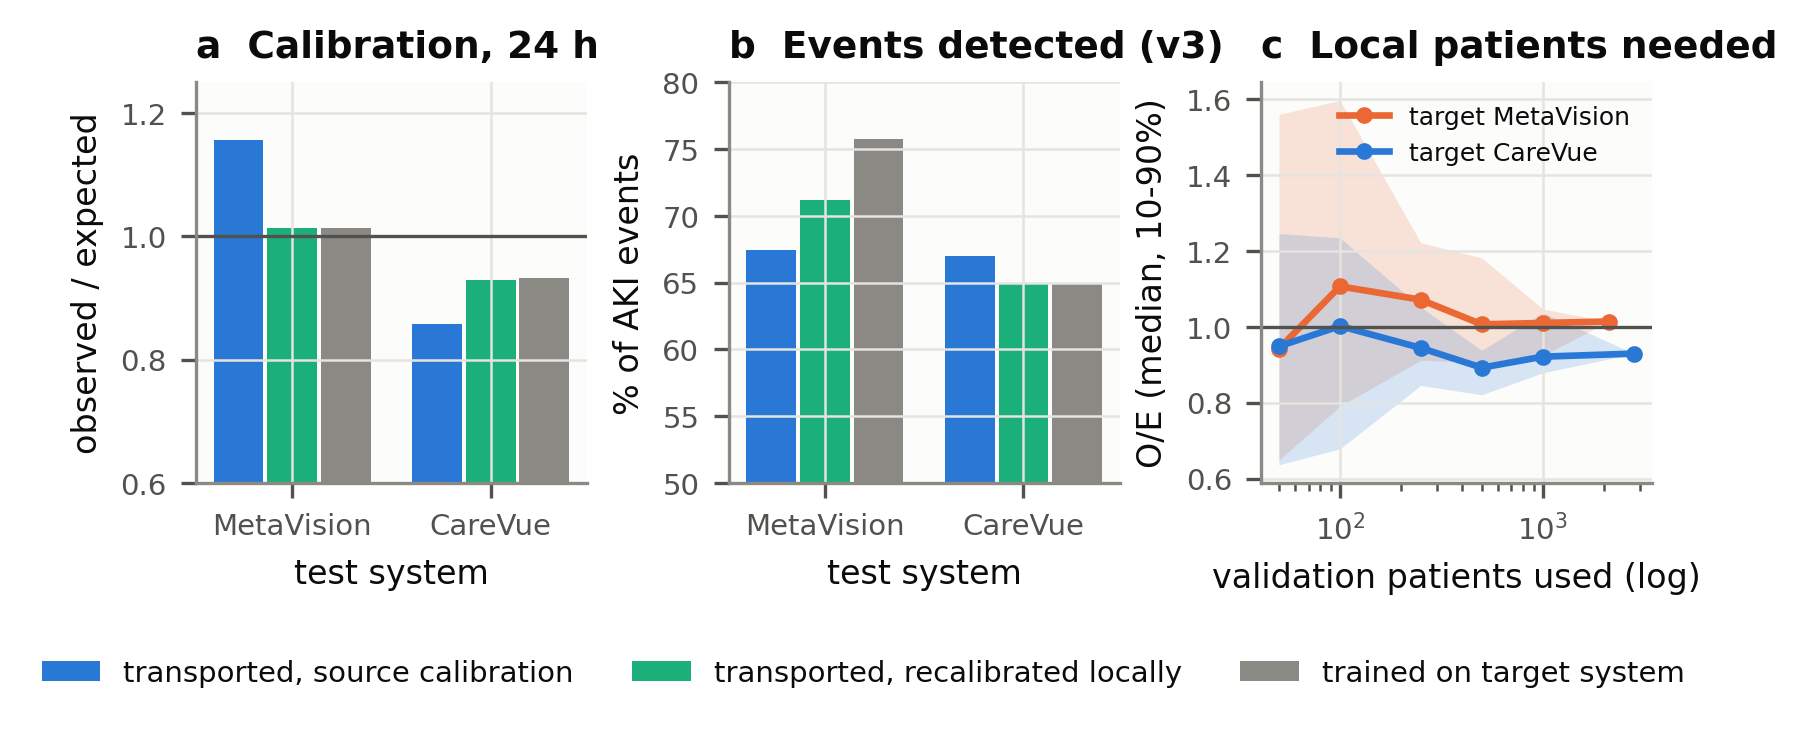

In [7]:
m = pd.read_csv(R / "system_shift_v1" / "snapshot_metrics.csv")
display(m[m["split"] == "test"].pivot_table(index=["target_system", "model"], columns="horizon_h", values="auroc"))
show("fig_system_shift")
r = pd.read_csv(R / "system_recalibration_v1" / "alert_metrics_policy_v3.csv")
display(r)
show("fig_recalibration")

## 6. Fairness by insurance and recorded ethnicity

,variable,level,patients,aki_events,reported,auroc_24h,auroc_ci_low,auroc_ci_high,observed_over_expected,event_detection_rate,false_alerts_per_patient_day
0,insurance,Medicare,2581,568,full,0.818,0.800,0.835,0.975,0.759,0.279
1,insurance,Private,1751,278,full,0.807,0.777,0.836,0.906,0.665,0.181
2,insurance,Medicaid,394,70,full,0.813,0.761,0.865,1.164,0.643,0.150
3,insurance,Government,163,35,full,0.831,0.725,0.917,1.452,0.629,0.119
4,insurance,Self Pay,70,8,counts only,NaN,NaN,NaN,NaN,NaN,NaN
5,ethnicity_group,WHITE,3536,645,full,0.820,0.802,0.837,0.929,0.727,0.227
6,ethnicity_group,BLACK,345,55,full,0.793,0.721,0.860,1.068,0.727,0.167
7,ethnicity_group,HISPANIC,160,28,full,0.828,0.758,0.892,1.176,0.536,0.160
8,ethnicity_group,ASIAN,125,23,full,0.852,0.786,0.910,1.062,0.696,0.172
9,ethnicity_group,OTHER,125,37,full,0.817,0.744,0.878,1.376,0.730,0.279


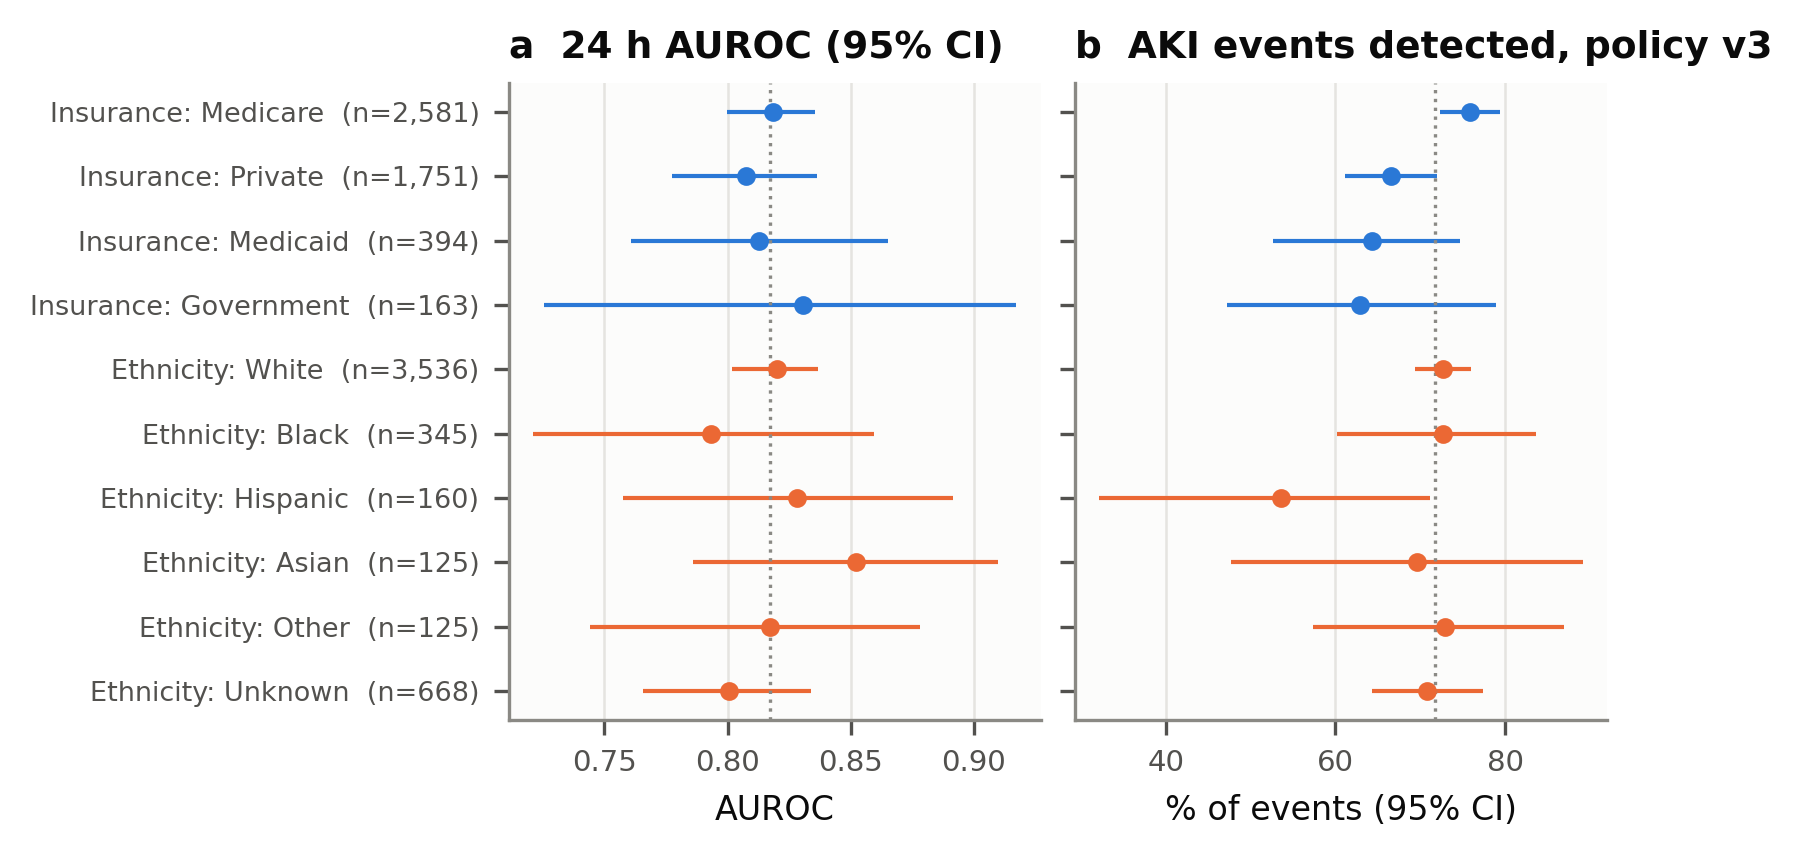

In [8]:
f = pd.read_csv(R / "fairness_structured_v1" / "fairness_by_group.csv")
display(f[f["analysis"] == "test"][["variable", "level", "patients", "aki_events", "reported", "auroc_24h", "auroc_ci_low", "auroc_ci_high", "observed_over_expected", "event_detection_rate", "false_alerts_per_patient_day"]])
show("fig_fairness")